# Локальные эмбеддинги: fastText, маленький BERT и ONNX Runtime

В этой лекции — три способа получить вектор текста **на обычном CPU, без GPU и без внешних API**:

1. **fastText** — статические векторы слов, обученные с учётом символьных n-грамм (субслов).
   Разберём, как получить готовые русские векторы и как обучить компактную модель под свой корпус.
2. **Маленький BERT** (`cointegrated/rubert-tiny2`, 29 млн параметров) — контекстные векторы:
   одно и то же слово в разных предложениях получает разные векторы.
3. **ONNX Runtime** — как вынести BERT из PyTorch в переносимый граф, ускорить инференс
   и сжать модель квантованием до int8.

Сравнивать методы будем не «на глаз», а на маленьком размеченном наборе из RuBQ:
8 вопросов и по 4 абзаца-кандидата (1 с ответом + 3 «сложных» отрицательных из той же статьи).

Что нужно помнить сразу:
- документы и запросы кодируются **одной и той же** моделью; векторы разных моделей несравнимы;
- статический вектор слова один на все контексты, контекстный — зависит от предложения;
- качество поиска определяет обучение модели, а не формат хранения (ONNX сам по себе качество не меняет).

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gensim.models import FastText
from gensim.utils import simple_preprocess

warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path.cwd()))
from search_common import (  # noqa: E402  (модуль курса: загрузка RuBQ и BM25)
    BM25Index,
    load_paragraphs,
    load_questions,
    metrics_from_ranks,
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE_DIR = Path.cwd().parent          # каталог 8_rag_and_search
MODELS_DIR = BASE_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
ONNX_DIR = MODELS_DIR / "onnx"
ONNX_DIR.mkdir(exist_ok=True)

print("python       :", sys.version.split()[0])
print("torch        :", torch.__version__)
print("потоков CPU  :", os.cpu_count())
print("каталог лекций:", Path.cwd())
print("кэш моделей  :", MODELS_DIR)

python       : 3.10.12
torch        : 2.1.1+cpu
потоков CPU  : 8
каталог лекций: /home/alex/bb_courses/use_ai_kstu/8_rag_and_search/lectures
кэш моделей  : /home/alex/bb_courses/use_ai_kstu/8_rag_and_search/models


## 1. Данные: корпус для обучения и мини-бенчмарк для проверки

Корпус — абзацы RuBQ 2.0 (русская Википедия, ≈57 тыс. абзацев). Из них возьмём **20 тыс.**
как учебный корпус для fastText: этого достаточно, чтобы векторы были осмысленными,
а обучение занимало десятки секунд.

Мини-бенчмарк повторяет ноутбук 02: 8 вопросов dev-набора, к каждому — абзац с ответом
и 3 абзаца **из той же статьи** без ответа. Тема и слова похожи, поэтому случайно угадать нельзя.

In [2]:
texts = load_paragraphs()
dev = load_questions("dev")
print("абзацев в корпусе:", len(texts))
print("вопросов в dev   :", len(dev))

candidates = dev[dev.apply(lambda r: len(set(r["related"]) - r["relevant"]) >= 3, axis=1)]
picked = candidates.sample(8, random_state=SEED).reset_index(drop=True)

mini_uids = []
for _, row in picked.iterrows():
    positive = min(row["relevant"])
    negatives = sorted(set(row["related"]) - row["relevant"])[:3]
    for uid in [positive] + negatives:
        if uid not in mini_uids:
            mini_uids.append(uid)

mini_relevant = [row["relevant"] & set(mini_uids) for _, row in picked.iterrows()]
mini_questions = picked["question_text"].tolist()
mini_texts = [texts[uid] for uid in mini_uids]

print("кандидатов в мини-корпусе:", len(mini_uids))
print("длина абзаца в среднем, символов:", int(np.mean([len(t) for t in texts])))
picked[["question_text", "answer_text"]].head(3)

абзацев в корпусе: 56952
вопросов в dev   : 444
кандидатов в мини-корпусе: 32
длина абзаца в среднем, символов: 448


,question_text,answer_text
0,Когда был учрежден Правительствующий сенат?,22.02.1711
1,В какой стране находится стадион «Маракана»?,Бразилия
2,Какая страна - родина бейсбола?,Англия


## 2. fastText: слово как сумма субслов

Идея fastText: слово представляется не отдельным вектором, а суммой векторов своих
символьных n-грамм. Для слова `банк` при `min_n=3, max_n=5` это `<ба`, `бан`, `анк`, `нк>`
и т. д. (границы слова тоже входят в n-граммы).

Отсюда два свойства:
- **морфология**: `футбол`, `футбола`, `футболу` делят n-граммы и оказываются рядом;
- **опечатки и редкие слова**: у слова, которого не было в словаре, вектор всё равно есть —
  он собирается из субслов (`парольь` не «падает» с `KeyError`).

Вектор предложения из статических векторов получают усреднением векторов слов
(mean pooling) и L2-нормировкой. Порядок слов при этом теряется.

### Готовые русские векторы и почему в классе своя модель

Официальные «готовые» векторы fastText для русского — `cc.ru.300` (Common Crawl + Wikipedia,
300 измерений, ≈7.2 ГБ в формате `.bin`):
`https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ru.300.bin.gz`.
Их загружают так (нужен пакет `fasttext`):

```python
import fasttext
ft = fasttext.load_model("cc.ru.300.bin")
v = ft.get_word_vector("пароль")        # np.ndarray, 300 чисел
for word in ["пароля", "пароли", "парольь"]:
    print(word, ft.get_word_vector(word)[:3])
```

В ноутбуке мы не тянем 7 ГБ: обучаем маленькую модель **тем же алгоритмом** (skip-gram
с субсловами и negative sampling) на 20 тыс. русских абзацев. Это честный компромисс:
словарь меньше, качество ниже, зато обучение занимает секунды и всё воспроизводимо.
Библиотека `gensim` реализует обучение fastText и умеет читать официальные `.bin`-модели
(`gensim.models.fasttext.load_facebook_vectors`). Для обучения в ноутбуке достаточно
`gensim`: отдельный пакет `fasttext` нужен только чтобы читать официальную `.bin`-модель.

Обученная модель кэшируется в `models/fasttext_rubq_100d.model`, поэтому повторный запуск
ноутбука не переобучает её.

In [3]:
FASTTEXT_PATH = MODELS_DIR / "fasttext_rubq_100d.model"
N_TRAIN_PARAGRAPHS = 20_000

t0 = time.perf_counter()
if FASTTEXT_PATH.exists():
    ft_model = FastText.load(str(FASTTEXT_PATH))
    train_seconds = 0.0
    print("загрузили обученную модель с диска:", FASTTEXT_PATH.name)
else:
    corpus = [simple_preprocess(t, deacc=False) for t in texts[:N_TRAIN_PARAGRAPHS]]
    ft_model = FastText(
        vector_size=100,
        window=5,
        min_count=10,
        sg=1,               # skip-gram
        negative=5,
        min_n=3,
        max_n=5,
        epochs=5,
        workers=4,
        bucket=200_000,     # сколько n-грамм хранить (влияет на размер файла)
        seed=SEED,
    )
    ft_model.build_vocab(corpus)
    ft_model.train(corpus, total_examples=len(corpus), epochs=ft_model.epochs)
    ft_model.save(str(FASTTEXT_PATH))
    train_seconds = time.perf_counter() - t0
    print(f"обучили fastText на {N_TRAIN_PARAGRAPHS} абзацах за {train_seconds:.1f} с")

wv = ft_model.wv
print("размерность вектора :", wv.vector_size)
print("слов в словаре      :", len(wv))

обучили fastText на 20000 абзацах за 18.9 с
размерность вектора : 100
слов в словаре      : 15558


### Почему модель занимает сотни мегабайт

Кроме векторов слов fastText хранит матрицу векторов n-грамм: `bucket × dim × 4` байта.
У gensim по умолчанию `bucket = 2_000_000`, то есть 800 МБ на 100 измерений; здесь задано
200 000 (80 МБ). У `cc.ru.300` такие матрицы и дают гигабайты на диске.

### Ближайшие соседи и субсловá

Посмотрим на соседей нескольких слов. Ожидаем увидеть не «синонимы», а **формы того же слова
и однокоренные слова**: модель на 20 тыс. абзацев небольшая, и субсловá в ней доминируют.

In [4]:
for word in ["футбол", "река", "москва", "фильм"]:
    nearest = wv.most_similar(word, topn=5)
    print(f"{word:8s} → " + ", ".join(f"{w} ({s:.2f})" for w, s in nearest))

футбол   → футболе (0.98), футболу (0.97), футбола (0.94), футболом (0.92), футболиста (0.92)
река     → реки (0.85), реках (0.84), озера (0.84), рек (0.84), озеро (0.83)
москва   → москвы (0.83), московская (0.82), петербургская (0.82), мосс (0.80), мосгу (0.80)
фильм    → фильму (0.94), мосфильм (0.93), фильмам (0.93), мультфильм (0.91), телефильм (0.90)


Теперь то, чего не умеет обычный word2vec: слово, которого нет в словаре.

In [5]:
def word_vector(word):
    """Вектор слова: из словаря или собранный из субслов (для OOV)."""
    return np.asarray(wv[word], dtype=np.float32)


for word in ["футбол", "футбола", "футболу", "пароль", "парольь", "пароли"]:
    vec = word_vector(word)
    print(
        f"{word:9s} в словаре: {word in wv.key_to_index!s:5s} "
        f"норма: {np.linalg.norm(vec):.2f} "
        f"cos(футбол, {word}) = {np.dot(word_vector('футбол'), vec) / np.linalg.norm(word_vector('футбол')) / np.linalg.norm(vec):.2f}"
    )

футбол    в словаре: True  норма: 4.33 cos(футбол, футбол) = 1.00
футбола   в словаре: True  норма: 3.93 cos(футбол, футбола) = 0.94
футболу   в словаре: True  норма: 4.46 cos(футбол, футболу) = 0.97
пароль    в словаре: False норма: 2.49 cos(футбол, пароль) = 0.39
парольь   в словаре: False норма: 1.66 cos(футбол, парольь) = 0.39
пароли    в словаре: False норма: 2.51 cos(футбол, пароли) = 0.41


`парольь` в словаре отсутствует, но вектор получен: это среднее векторов субслов.
Такой вектор близок к `пароль`, хотя и «размыт» — модель никогда не видела это написание целиком.

### Вектор текста: усреднение слов

`mean pooling` — самый простой способ получить вектор документа из статических векторов.
Нормируем каждое слово, усредняем, нормируем результат: так длинные документы
не «перевешивают» короткие за счёт масштаба.

In [6]:
def embed_fasttext(text):
    """L2-нормированный mean-pooling векторов слов (размерность 100)."""
    tokens = simple_preprocess(text, deacc=False)
    if not tokens:
        return np.zeros(wv.vector_size, dtype=np.float32)
    matrix = np.stack([word_vector(t) for t in tokens])
    matrix /= np.linalg.norm(matrix, axis=1, keepdims=True) + 1e-9
    vec = matrix.mean(axis=0)
    return vec / (np.linalg.norm(vec) + 1e-9)


def embed_fasttext_many(items):
    return np.stack([embed_fasttext(t) for t in items])


sentences = [
    "Чтобы сбросить пароль, нажмите «Забыли пароль» на странице входа.",
    "Восстановление доступа к учётной записи и смена пароля.",
    "Курьер доставляет заказы ежедневно с девяти до двадцати одного часа.",
]
vecs = embed_fasttext_many(sentences)
sim = vecs @ vecs.T
print("cos(пароль-инструкция, восстановление доступа) =", round(float(sim[0, 1]), 3))
print("cos(пароль-инструкция, доставка)              =", round(float(sim[0, 2]), 3))

pd.DataFrame(sim, index=["пароль", "восстановление", "доставка"], columns=["пароль", "восстановление", "доставка"]).round(3)

cos(пароль-инструкция, восстановление доступа) = 0.783
cos(пароль-инструкция, доставка)              = 0.779


,пароль,восстановление,доставка
пароль,1.000,0.783,0.779
восстановление,0.783,1.000,0.779
доставка,0.779,0.779,1.000


Что видно: оба косинуса почти одинаковы (~0.77, разница в третьем знаке). У предложений
нет общих слов, а «пароль» и «пароли» в этом корпусе — OOV, поэтому mean-pooling не различает
«восстановление доступа» и «доставку заказа». Это не баг реализации, а свойство метода:
усреднённые статические векторы не умеют связывать синонимы и теряют порядок слов.
Отсюда и следующий шаг — контекстные модели.

### Мини-бенчмарк: fastText против BM25

BM25 строим по всему корпусу (чтобы IDF был честным), но ранжируем только 32 абзаца
мини-корпуса — так оба метода выбирают из одних и тех же кандидатов.

In [7]:
bm25 = BM25Index(texts)

mini_fasttext_docs = embed_fasttext_many(mini_texts)
mini_fasttext_queries = embed_fasttext_many(mini_questions)
mini_scores = {
    "BM25 (стемы-4)": bm25.scores(mini_questions)[:, mini_uids],
    "fastText-mean (100d)": mini_fasttext_queries @ mini_fasttext_docs.T,
}


def ranks_on_mini(scores):
    """Ранг первого релевантного абзаца для каждого вопроса."""
    ranks = []
    for row, relevant in zip(scores, mini_relevant):
        ordered = [mini_uids[j] for j in np.argsort(-row)]
        ranks.append(1 + next(i for i, uid in enumerate(ordered) if uid in relevant))
    return np.array(ranks)


mini_ranks = {name: ranks_on_mini(s) for name, s in mini_scores.items()}
mini_metrics = pd.DataFrame({name: metrics_from_ranks(r) for name, r in mini_ranks.items()}).T
mini_metrics.round(3)

,Hit@1,Hit@5,Hit@10,Hit@20,MRR@10
BM25 (стемы-4),0.75,1.00,1.000,1.0,0.854
fastText-mean (100d),0.25,0.75,0.875,1.0,0.466


## 3. Маленький BERT на CPU

fastText даёт **один** вектор на слово. BERT считает вектор токена в контексте всего предложения:
те же веса, но разные входы → разные векторы. Отсюда:

- `последний скрытый слой` — матрица `(батч, токены, 312)`;
- `CLS-pooling` — вектор специального токена `[CLS]`;
- `mean-pooling` — среднее по токенам с учётом `attention_mask` (паддинг не учитываем).

Возьмём `cointegrated/rubert-tiny2`: 3 слоя, 312 измерений, ≈29 млн параметров (≈117 МБ во float32).
Модель дистиллирована из `rubert-base` и хорошо работает на CPU, **но не обучалась на парах
«вопрос — ответ»**: её векторы — не готовый поисковый эмбеддинг, а отправная точка.
Для поиска такие модели дообучают (contrastive learning) или берут retrieval-модели вроде E5.

In [8]:
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

BERT_NAME = "cointegrated/rubert-tiny2"
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert = AutoModel.from_pretrained(BERT_NAME).eval()

n_params = sum(p.numel() for p in bert.parameters())
print("модель             :", BERT_NAME)
print("параметров         :", f"{n_params:,}".replace(",", " "))
print("скрытая размерность:", bert.config.hidden_size)
print("слоёв              :", bert.config.num_hidden_layers)

batch = tokenizer(
    ["Сброс пароля на странице входа.", "Курьер доставит заказ завтра."],
    padding=True,
    truncation=True,
    return_tensors="pt",
)
print("\nтокены 1-го текста:", tokenizer.convert_ids_to_tokens(batch["input_ids"][0]))
with torch.no_grad():
    hidden = bert(**batch).last_hidden_state
print("форма скрытых состояний:", tuple(hidden.shape), "= (батч, токены, 312)")
print("форма CLS-векторов     :", tuple(hidden[:, 0].shape))

модель             : cointegrated/rubert-tiny2
параметров         : 29 193 768
скрытая размерность: 312
слоёв              : 3

токены 1-го текста: ['[CLS]', 'С', '##брос', 'пароля', 'на', 'странице', 'входа', '.', '[SEP]']


форма скрытых состояний: (2, 9, 312) = (батч, токены, 312)
форма CLS-векторов     : (2, 312)


### Контекстность: одно слово — разные векторы

Слово «ключ» в трёх предложениях: инструмент, ключ от квартиры, ключ API.
У fastText это **один и тот же** вектор, у BERT — три разных.

In [9]:
context_sentences = [
    "Гаечный ключ лежал в ящике с инструментами.",
    "Я потерял ключ от квартиры и не смог войти.",
    "Сервис выдаёт ключ API в личном кабинете.",
]
context_labels = ["инструмент", "от квартиры", "API"]


def contextual_word_vector(sentence, word="ключ"):
    """L2-нормированный вектор слова с учётом контекста предложения."""
    encoded = tokenizer(sentence, return_tensors="pt")
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
    position = tokens.index(word)
    with torch.no_grad():
        vec = bert(**encoded).last_hidden_state[0, position].numpy()
    return vec / np.linalg.norm(vec)


bert_key_vectors = np.stack([contextual_word_vector(s) for s in context_sentences])
fasttext_key_vector = word_vector("ключ")
fasttext_key_vector /= np.linalg.norm(fasttext_key_vector)
fasttext_key_vectors = np.stack([fasttext_key_vector] * 3)

sim_bert = bert_key_vectors @ bert_key_vectors.T
sim_fasttext = fasttext_key_vectors @ fasttext_key_vectors.T

pd.DataFrame(
    sim_bert,
    index=[f"ключ ({name})" for name in context_labels],
    columns=context_labels,
).round(3)

,инструмент,от квартиры,API
ключ (инструмент),1.000,0.641,0.649
ключ (от квартиры),0.641,1.000,0.709
ключ (API),0.649,0.709,1.000


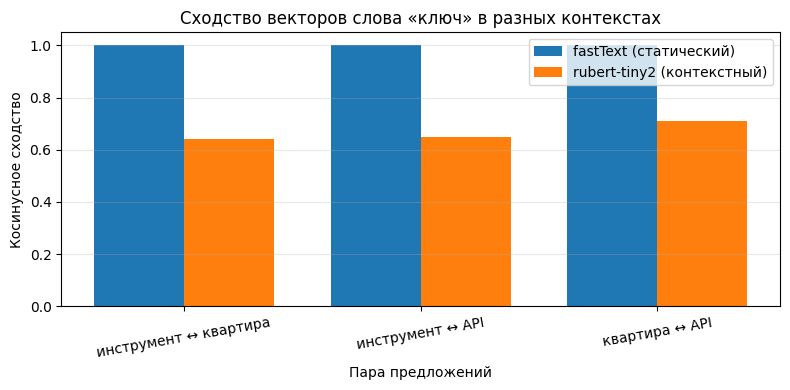

In [10]:
pairs = [(0, 1), (0, 2), (1, 2)]
pair_labels = ["инструмент ↔ квартира", "инструмент ↔ API", "квартира ↔ API"]

x = np.arange(len(pairs))
width = 0.38
plt.figure(figsize=(8, 4))
plt.bar(x - width / 2, [sim_fasttext[i, j] for i, j in pairs], width, label="fastText (статический)")
plt.bar(x + width / 2, [sim_bert[i, j] for i, j in pairs], width, label="rubert-tiny2 (контекстный)")
plt.xticks(x, pair_labels, rotation=10)
plt.ylim(0, 1.05)
plt.title("Сходство векторов слова «ключ» в разных контекстах")
plt.xlabel("Пара предложений")
plt.ylabel("Косинусное сходство")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

У fastText все три косинуса равны 1.0: вектор слова не зависит от предложения.
У BERT косинусы в диапазоне 0.64–0.71: контекст влияет, но у 3-слойной tiny-модели
эффект умеренный — не ждите, что она идеально разделит значения слова.
Главное отличие не в величине, а в самом факте: fastText даёт один вектор на все контексты,
BERT — свой в каждом предложении. За это платим полным проходом модели на каждый текст.

### Кодируем тексты: mean-pooling в батчах

Батчи важны: на одном предложении накладные расходы съедают всё преимущество.
Заодно сравним два pooling-а на паре перефраз.

In [11]:
@torch.no_grad()
def encode_bert(items, batch_size=16, max_length=128, pooling="mean"):
    """L2-нормированные векторы предложений (312 измерений)."""
    result = []
    for start in range(0, len(items), batch_size):
        encoded = tokenizer(
            items[start : start + batch_size],
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )
        hidden = bert(**encoded).last_hidden_state
        if pooling == "cls":
            pooled = hidden[:, 0]
        else:
            mask = encoded["attention_mask"].unsqueeze(-1).float()
            pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1)
        result.append(F.normalize(pooled, dim=1).numpy())
    return np.concatenate(result)


paraphrases = [
    "Чтобы сбросить пароль, нажмите «Забыли пароль» на странице входа.",
    "Восстановление доступа к учётной записи и смена пароля.",
    "Курьер доставляет заказы ежедневно с девяти до двадцати одного часа.",
]
for pooling in ["cls", "mean"]:
    vecs_p = encode_bert(paraphrases, pooling=pooling)
    print(
        f"pooling={pooling:4s}: cos(пароль, восстановление) = {vecs_p[0] @ vecs_p[1]:.3f}, "
        f"cos(пароль, доставка) = {vecs_p[0] @ vecs_p[2]:.3f}"
    )

t0 = time.perf_counter()
mini_bert_docs = encode_bert(mini_texts)
mini_bert_queries = encode_bert(mini_questions, batch_size=8)
bert_seconds = time.perf_counter() - t0

n_texts = len(mini_texts) + len(mini_questions)
print(f"\nBERT: {n_texts} текстов за {bert_seconds:.2f} с = {n_texts / bert_seconds:.1f} текстов/с")
print(f"оценка на весь корпус (57 тыс. абзацев): ~{len(texts) / (n_texts / bert_seconds) / 60:.1f} мин на CPU")
print("размерность вектора BERT:", mini_bert_docs.shape[1])

pooling=cls : cos(пароль, восстановление) = 0.719, cos(пароль, доставка) = 0.288
pooling=mean: cos(пароль, восстановление) = 0.643, cos(пароль, доставка) = 0.228



BERT: 40 текстов за 0.38 с = 104.4 текстов/с
оценка на весь корпус (57 тыс. абзацев): ~9.1 мин на CPU
размерность вектора BERT: 312


### Мини-бенчмарк: fastText, BERT и BM25

Добавляем BERT-mean в ту же таблицу. Важно: BERT здесь **без дообучения**.

In [12]:
mini_scores["rubert-tiny2 mean (312d)"] = mini_bert_queries @ mini_bert_docs.T
mini_ranks = {name: ranks_on_mini(s) for name, s in mini_scores.items()}
mini_metrics = pd.DataFrame({name: metrics_from_ranks(r) for name, r in mini_ranks.items()}).T
mini_metrics.round(3)

,Hit@1,Hit@5,Hit@10,Hit@20,MRR@10
BM25 (стемы-4),0.750,1.000,1.000,1.0,0.854
fastText-mean (100d),0.250,0.750,0.875,1.0,0.466
rubert-tiny2 mean (312d),0.625,0.875,0.875,1.0,0.712


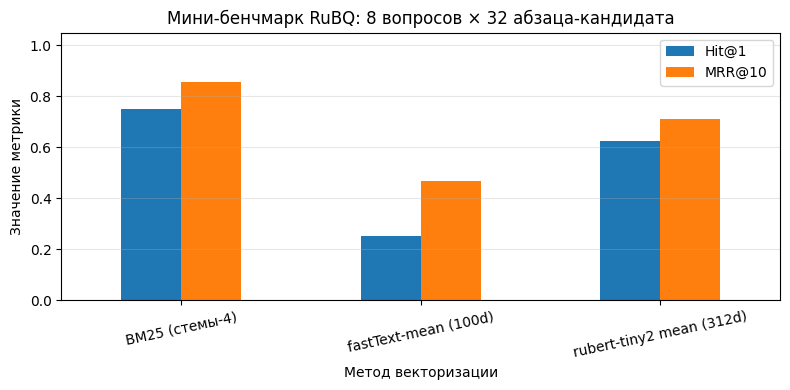

In [13]:
figure, axis = plt.subplots(figsize=(8, 4))
mini_metrics[["Hit@1", "MRR@10"]].plot.bar(ax=axis, rot=12)
axis.set_title("Мини-бенчмарк RuBQ: 8 вопросов × 32 абзаца-кандидата")
axis.set_xlabel("Метод векторизации")
axis.set_ylabel("Значение метрики")
axis.set_ylim(0, 1.05)
axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

8 вопросов — иллюстрация, а не измерение: одна ошибка сдвигает Hit@1 на 12.5 п.п.
В контрольном запуске получилось: BM25 — Hit@1 0.75, `rubert-tiny2` mean — 0.625,
fastText-mean — 0.25. Восемь вопросов — иллюстрация, а не измерение: одна ошибка
сдвигает Hit@1 на 12.5 п.п. Но два вывода устойчивы:
- контекстные векторы без дообучения обгоняют статические, но всë равно проигрывают BM25
  на фактологических вопросах, где ответ и вопрос делят редкие слова (имена, даты, термины);
- качество задано обучением модели, а не архитектурой: `rubert-tiny2` — языковая модель,
  а не retrieval-модель.
Для честного сравнения нужен большой размеченный набор и модель, обученная на парах
«вопрос — отвечающий фрагмент» (например, E5).

## 4. ONNX Runtime: тот же BERT без PyTorch

ONNX — формат графа вычислений. Модель один раз экспортируется из PyTorch, а исполняется
затем любым ONNX-рантаймом (Python, C++, C#, мобильные платформы). Что это даёт на практике:

- на сервере не нужен PyTorch (меньше зависимостей и образ контейнера);
- ONNX Runtime оптимизирует граф под CPU (слияние операторов, свои ядра);
- доступно квантование: веса можно хранить в int8 — модель меньше в 4 раза, а скорость
  зависит от процессора (для маленького BERT выигрыш может быть нулевым).

Экспорт не меняет математику: проверяем это численно. Осторожно с двумя вещами:
динамические оси (`batch`, `seq`) нужно указать явно, иначе модель зафиксирует размер входа;
pooling делаем **снаружи** графа, чтобы ONNX-модель возвращала те же скрытые состояния.

Альтернатива ручному экспорту — `optimum-cli export onnx --model cointegrated/rubert-tiny2`.

In [14]:
import onnx
import onnxruntime as ort
from onnxruntime.quantization import QuantType, quantize_dynamic

ONNX_PATH = ONNX_DIR / f"{BERT_NAME.split('/')[-1]}.onnx"
ONNX_INT8_PATH = ONNX_DIR / f"{BERT_NAME.split('/')[-1]}_int8.onnx"


class BertEncoder(torch.nn.Module):
    """Обёртка: возвращает только last_hidden_state, чтобы граф был простым."""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, input_ids, attention_mask, token_type_ids):
        outputs = self.model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
        )
        return outputs.last_hidden_state


encoder = BertEncoder(bert).eval()
dummy = tokenizer(["тест"] * 2, padding="max_length", max_length=8, truncation=True, return_tensors="pt")
input_names = ["input_ids", "attention_mask", "token_type_ids"]
dynamic_axes = {name: {0: "batch", 1: "seq"} for name in input_names}
dynamic_axes["last_hidden_state"] = {0: "batch", 1: "seq"}

if not ONNX_PATH.exists():
    t0 = time.perf_counter()
    torch.onnx.export(
        encoder,
        (dummy["input_ids"], dummy["attention_mask"], dummy["token_type_ids"]),
        str(ONNX_PATH),
        input_names=input_names,
        output_names=["last_hidden_state"],
        dynamic_axes=dynamic_axes,
        opset_version=14,
        do_constant_folding=True,
    )
    print(f"экспорт занял {time.perf_counter() - t0:.1f} с")
else:
    print("ONNX-модель уже есть, экспорт пропущен")

onnx_model = onnx.load(str(ONNX_PATH))
print("opset:", onnx_model.opset_import[0].version)
print("размер fp32, МБ:", round(ONNX_PATH.stat().st_size / 1e6, 1))

экспорт занял 1.1 с
opset: 14
размер fp32, МБ: 116.5


### Проверяем, что ONNX-граф считает то же самое

In [15]:
def make_session(path, threads=4):
    options = ort.SessionOptions()
    options.intra_op_num_threads = threads
    options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    options.log_severity_level = 3
    return ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])


session_fp32 = make_session(ONNX_PATH)
print("входы :", [(i.name, i.shape) for i in session_fp32.get_inputs()])
print("выходы:", [(o.name, o.shape) for o in session_fp32.get_outputs()])

check = tokenizer(paraphrases, padding=True, truncation=True, max_length=64, return_tensors="pt")
with torch.no_grad():
    reference = encoder(**check).numpy()
onnx_inputs = {name: check[name].numpy() for name in input_names}
exported = session_fp32.run(None, onnx_inputs)[0]

print("\nформа выхода           :", exported.shape)
print("max |torch - onnx|     :", f"{np.abs(reference - exported).max():.2e}")
print("cos(векторы, развёрнуто):", f"{np.dot(reference.ravel(), exported.ravel()) / np.linalg.norm(reference) / np.linalg.norm(exported):.6f}")

входы : [('input_ids', ['batch', 'seq']), ('attention_mask', ['batch', 'seq']), ('token_type_ids', ['batch', 'seq'])]
выходы: [('last_hidden_state', ['batch', 'seq', 312])]



форма выхода           : (3, 17, 312)
max |torch - onnx|     : 5.36e-06
cos(векторы, развёрнуто): 1.000000


### Квантование int8

`quantize_dynamic` не требует калибровочного набора: веса матмулов переводятся в int8,
активации квантуются на лету. Модель становится примерно в 4 раза меньше, а выигрыш
по скорости не гарантирован: у маленького BERT накладные расходы квантования могут
съесть всю экономию — это нормальный результат, его надо измерять.

In [16]:
if not ONNX_INT8_PATH.exists():
    quantize_dynamic(str(ONNX_PATH), str(ONNX_INT8_PATH), weight_type=QuantType.QUInt8)
    print("квантование выполнено")

session_int8 = make_session(ONNX_INT8_PATH)
quantized = session_int8.run(None, onnx_inputs)[0]


def mean_pool_numpy(hidden, attention_mask):
    mask = attention_mask[..., None].astype(np.float32)
    pooled = (hidden * mask).sum(axis=1) / mask.sum(axis=1)
    return pooled / (np.linalg.norm(pooled, axis=1, keepdims=True) + 1e-9)


pooled_fp32 = mean_pool_numpy(exported, onnx_inputs["attention_mask"])
pooled_int8 = mean_pool_numpy(quantized, onnx_inputs["attention_mask"])

diffs = [1 - float(a @ b) for a, b in zip(pooled_fp32, pooled_int8)]
for text, diff in zip(paraphrases, diffs):
    print(f"1 - cos(fp32, int8) = {diff:.4f}  | {text[:50]}…")

sizes = pd.DataFrame(
    {
        "формат": ["PyTorch (fp32, в памяти)", "ONNX fp32", "ONNX int8"],
        "размер, МБ": [
            n_params * 4 / 1e6,
            ONNX_PATH.stat().st_size / 1e6,
            ONNX_INT8_PATH.stat().st_size / 1e6,
        ],
    }
)
sizes.round(1)

квантование выполнено
1 - cos(fp32, int8) = 0.0023  | Чтобы сбросить пароль, нажмите «Забыли пароль» на …
1 - cos(fp32, int8) = 0.0023  | Восстановление доступа к учётной записи и смена па…
1 - cos(fp32, int8) = 0.0025  | Курьер доставляет заказы ежедневно с девяти до два…


,формат,"размер, МБ"
0,"PyTorch (fp32, в памяти)",116.8
1,ONNX fp32,116.5
2,ONNX int8,29.3


### Скорость: PyTorch против ONNX Runtime

Меряем одинаковый вход: батч из 32 текстов, длина 64 токена, 4 потока CPU,
после прогрева — медиана по 10 запускам. Числа зависят от процессора, важен порядок.

In [17]:
torch.set_num_threads(4)

bench = tokenizer(
    [t[:400] for t in texts[:32]],
    padding="max_length",
    max_length=64,
    truncation=True,
    return_tensors="pt",
)
bench_inputs = {name: bench[name].numpy() for name in input_names}
N_RUNS = 10


def time_torch(n_runs=N_RUNS):
    with torch.no_grad():
        for _ in range(3):
            encoder(**bench)
        t0 = time.perf_counter()
        for _ in range(n_runs):
            encoder(**bench)
    return (time.perf_counter() - t0) / n_runs * 1000


def time_onnx(session, n_runs=N_RUNS):
    for _ in range(3):
        session.run(None, bench_inputs)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        session.run(None, bench_inputs)
    return (time.perf_counter() - t0) / n_runs * 1000


timings = {
    "PyTorch fp32": time_torch(),
    "ONNX fp32": time_onnx(session_fp32),
    "ONNX int8": time_onnx(session_int8),
}
for name, ms in timings.items():
    print(f"{name:13s}: {ms:6.1f} мс на батч из 32 текстов = {32 / ms * 1000:5.0f} текстов/с")

PyTorch fp32 :  140.4 мс на батч из 32 текстов =   228 текстов/с
ONNX fp32    :   90.2 мс на батч из 32 текстов =   355 текстов/с
ONNX int8    :   85.3 мс на батч из 32 текстов =   375 текстов/с


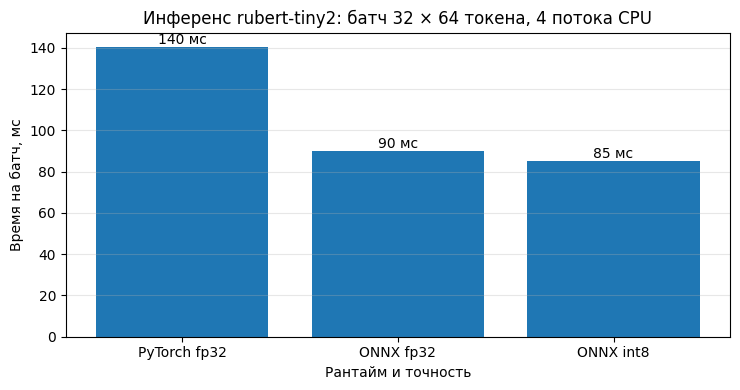

In [18]:
plt.figure(figsize=(7.5, 4))
bars = plt.bar(list(timings), list(timings.values()))
for bar, ms in zip(bars, timings.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, ms, f"{ms:.0f} мс", ha="center", va="bottom")
plt.title("Инференс rubert-tiny2: батч 32 × 64 токена, 4 потока CPU")
plt.xlabel("Рантайм и точность")
plt.ylabel("Время на батч, мс")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Квантование и качество поиска

Уменьшение модели бессмысленно, если меняется выдача. Прогоним мини-бенчмарк
через int8-модель и сравним с float32.

In [19]:
def encode_onnx(items, session, batch_size=16, max_length=128):
    """Mean-pooling поверх ONNX-графа."""
    result = []
    for start in range(0, len(items), batch_size):
        encoded = tokenizer(
            items[start : start + batch_size],
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )
        inputs = {name: encoded[name].numpy() for name in input_names}
        hidden = session.run(None, inputs)[0]
        result.append(mean_pool_numpy(hidden, inputs["attention_mask"]))
    return np.concatenate(result)


onnx_int8_docs = encode_onnx(mini_texts, session_int8)
onnx_int8_queries = encode_onnx(mini_questions, session_int8)

cosine_to_torch = np.sum(mini_bert_docs * onnx_int8_docs, axis=1)
print("cos(torch, onnx int8) по абзацам: min =", f"{cosine_to_torch.min():.4f}",
      ", среднее =", f"{cosine_to_torch.mean():.4f}")

mini_scores["ONNX int8 mean (312d)"] = onnx_int8_queries @ onnx_int8_docs.T
mini_ranks["ONNX int8 mean (312d)"] = ranks_on_mini(mini_scores["ONNX int8 mean (312d)"])
print("ранги torch :", list(mini_ranks["rubert-tiny2 mean (312d)"]))
print("ранги int8  :", list(mini_ranks["ONNX int8 mean (312d)"]))

pd.DataFrame({name: metrics_from_ranks(r) for name, r in mini_ranks.items()}).T.round(3)

cos(torch, onnx int8) по абзацам: min = 0.9968 , среднее = 0.9976
ранги torch : [1, 1, 11, 1, 2, 1, 5, 1]
ранги int8  : [1, 1, 12, 1, 2, 1, 5, 1]


,Hit@1,Hit@5,Hit@10,Hit@20,MRR@10
BM25 (стемы-4),0.750,1.000,1.000,1.0,0.854
fastText-mean (100d),0.250,0.750,0.875,1.0,0.466
rubert-tiny2 mean (312d),0.625,0.875,0.875,1.0,0.712
ONNX int8 mean (312d),0.625,0.875,0.875,1.0,0.712


На этом запуске ранги почти совпали: один вопрос сместился с 11-го на 12-е место,
а Hit@1 не изменился. Квантование слегка сдвигает векторы, и именно поэтому его влияние
проверяют по метрикам поиска, а не «на глаз».

## 5. Итоги

| Подход | Вектор | Плюсы | Минусы | Когда брать |
|---|---:|---|---|---|
| fastText (свой или `cc.ru.300`) | 100–300 | быстро, дёшево, офлайн, субсловá | нет контекста, порядок слов теряется | большие корпуса, базовый semantic search |
| rubert-tiny2, PyTorch | 312 | контекст, мало весов, простой код | медленнее, нужен PyTorch | прототипы, дообучение |
| rubert-tiny2 → ONNX Runtime | 312 | переносимо, быстрее, нет PyTorch на сервере | нужны экспорт и валидация | сервис, edge, CPU-инференс |
| ONNX int8 | 312 | в 4 раза меньше; на части CPU быстрее fp32 | ошибка округления, выигрыш по скорости не гарантирован | продакшен с контролем качества |

Ни один вариант не отменяет главного: **поисковое качество задаётся обучением модели**.
ONNX и int8 ускоряют уже обученную модель, но не превращают `rubert-tiny2` в retrieval-модель.
Если нужен качественный поиск — берите retrieval-модель (E5 или `rubert-tiny2` после
contrastive fine-tuning) и измеряйте её на своём размеченном наборе.

In [20]:
t0 = time.perf_counter()
embed_fasttext_many([t[:400] for t in texts[:32]])
fasttext_ms = (time.perf_counter() - t0) * 1000
fasttext_size_mb = sum(p.stat().st_size for p in MODELS_DIR.glob("fasttext_rubq_100d*")) / 1e6

comparison = pd.DataFrame(
    {
        "размерность": [wv.vector_size, bert.config.hidden_size, bert.config.hidden_size],
        "время на 32 текста, мс": [fasttext_ms, timings["PyTorch fp32"], timings["ONNX int8"]],
        "размер модели, МБ": [
            fasttext_size_mb,
            n_params * 4 / 1e6,
            ONNX_INT8_PATH.stat().st_size / 1e6,
        ],
    },
    index=["fastText-mean", "rubert-tiny2 (torch)", "rubert-tiny2 (onnx int8)"],
)
comparison.round(1)

,размерность,"время на 32 текста, мс","размер модели, МБ"
fastText-mean,100,17.3,93.0
rubert-tiny2 (torch),312,140.4,116.8
rubert-tiny2 (onnx int8),312,85.3,29.3


## 6. Практикум

1. Обучите fastText на всех 57 тыс. абзацах (`N_TRAIN_PARAGRAPHS = len(texts)`) и сравните
   Hit@1 на мини-бенчмарке с моделью на 20 тыс. Сколько времени это заняло?
2. Скачайте официальные `cc.ru.300` и сравните соседей слова `банк` с вашей моделью.
   Объясните, почему векторы двух моделей нельзя сравнивать между собой.
3. Сравните `cls` и `mean` pooling на 30 парах перефраз: где CLS выигрывает и почему
   у `rubert-tiny2` это не гарантировано?
4. Проверьте ONNX-модель на батчах разной длины (8, 32, 128 токенов). Что сломается,
   если убрать `dynamic_axes`?
5. Повторите квантование с `per_channel=True` и `QuantType.QInt8`, сравните размер,
   скорость и `1 - cos` с float32.
6. Добавьте в мини-бенчмарк точное квантование E5-small (если есть GPU-время) и объясните,
   почему «лучшая модель» без дообучения может проиграть BM25 на фактологических вопросах.

**Критерий понимания:** студент объясняет, почему ONNX и int8 не улучшают качество поиска,
чем статический вектор слова отличается от контекстного, и почему отчёт о сжатии модели
без проверки метрик поиска недостаточен.

## Источники

1. [Bojanowski et al. Enriching Word Vectors with Subword Information](https://arxiv.org/abs/1607.04606) — статья fastText.
2. [fastText: pretrained vectors](https://fasttext.cc/docs/en/pretrained-vectors.html) и [crawl vectors](https://fasttext.cc/docs/en/crawl-vectors.html).
3. [gensim: FastText](https://radimrehurek.com/gensim/models/fasttext.html).
4. [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2) — model card.
5. [ONNX Runtime: quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html).
6. [torch.onnx.export](https://pytorch.org/docs/stable/onnx.html).
7. [Hugging Face Optimum: ONNX export](https://huggingface.co/docs/optimum/exporters/onnx/usage_guides/export_a_model).